In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import pandas as pd
from numpy import quantile

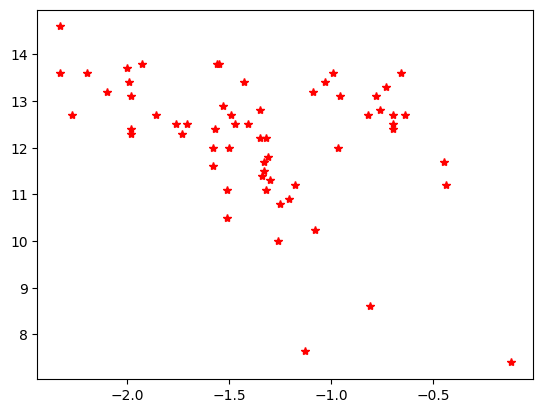

In [3]:
df = pd.read_csv('Krause21.csv')

Metallicity = df['FeH']
Age = df['Age']     # Age given in Myrs
Mstar = df['Mstar'] # Mass given in 10^5 solar masses
R_half = df['rh']   # Half mass radius for each star

plt.plot(Metallicity, Age, "r*")
plt.show()


In [4]:
# We want to compile all 4 of the data sets into one, but we only want to accept ID's that all four datasets have.
# The tricky thing is that the four datasets have different ways of displaying the ID's so each paragraph must format the ID's
# to be identical first. Then we find the intersection between the four sets.

krause21 = pd.read_csv('Krause21.csv')      # Read Csv File
data_id_krause = krause21["Object"]         # Only take "object" column (IDs)
# print(list(data_id_krause))
data_id_krause_fix = []                     # Here I'm creating an empty list, this will be the list of formatted IDs
for i in list(data_id_krause):              # for each ID tag
    if i[0:3] == "NGC":                     # if the first three letters are NGC
        j = i[3:]                           # then note the rest of the code
        # print(j)
        data_id_krause_fix.append(j)        # and add it to the empty list from above
    else:
        # print(i)
        data_id_krause_fix.append(i)
data_id_krause_fix = set(data_id_krause_fix)    # we want to turn the list into a set because a set will not care about order
print("krause: ", data_id_krause_fix)


harris1 = pd.read_csv('HarrisPartI.csv')        # Read Csv File 
data_id_harris1 = harris1["ID"]                 # Only take ID's
# print(list(data_id_harris1))
data_id_harris1_fix = []
for i in list(data_id_harris1):
    if i[0:3] == "NGC":                         # if the first letters are NGC
        j = i.split(" ")                        # split the string into 2 parts
        # print(j[1])
        data_id_harris1_fix.append(j[1])        # then add the second half
    else:
        # print(i)
        data_id_harris1_fix.append(i)
data_id_harris1_fix = set(data_id_harris1_fix)
print("harris1: ", data_id_harris1_fix)

harris3 = pd.read_csv('HarrisPartIII.csv')
data_id_harris3 = harris3["ID"]
# print(list(data_id_harris3))
data_id_harris3_fix = []
for i in list(data_id_harris3):
    if i[0:3] == "NGC":
        f = i.split(" ")
        # print(f[1])
        data_id_harris3_fix.append(f[1])
    else:
        # print(i)
        data_id_harris3_fix.append(i)
data_id_harris3_fix = set(data_id_harris3_fix)
print("harris3: ", data_id_harris3_fix)

vandenberg = pd.read_csv("vandenBerg_table2.csv")
data_id_vandenberg = vandenberg["#NGC"]
# print(list(data_id_vandenberg))
data_id_vandenberg_fix = set(data_id_vandenberg)
print("vandenberg: ", data_id_vandenberg_fix)

len(data_id_harris3_fix & data_id_harris1_fix & data_id_vandenberg_fix & data_id_krause_fix)
print(list(data_id_harris3_fix & data_id_harris1_fix & data_id_vandenberg_fix & data_id_krause_fix))



krause:  {'2808', '3201', '5904', '6171', '104', '6362', '2298', '5272', '5927', '6341', '5897', '6144', '5024', '6681', '288', '6254', '5466', '5286', '6981', '6304', '6388', '6101', '6496', '5986', '6535', '6139', '6218', '6656', '6779', 'Ruprecht106', '7099', '6205', '7078', '4833', '6715', '6752', '6352', '6934', '6584', '5053', '6366', 'Palomar12', '1904', '1261', '6717', '6652', '6723', '7089', '362', '4590', 'Terzan7', '6809', '6637', '6121', '6093', '6838', '6441', '6397', '1851', '6624', '6541'}
harris1:  {'6287', '6171', '3201', '6342', '2298', '5927', '6341', 'HP 1', '6760', '5024', '288', '6254', '6981', '6388', 'Terzan 6', '6496', 'BH 261', 'GLIMPSE01', 'Whiting 1', '6139', '6440', '6535', '6544', 'Djorg 1', '6656', 'FSR 1735', '6638', 'Ton 2', '2MS-GC01', '6642', '4833', 'Terzan 8', '6715', 'Pal 12', '6584', '5053', '6366', '6426', '6717', '6652', '6235', '6637', '5824', '6121', '6838', 'Pal 11', '6402', '1851', 'Liller 1', '5139', 'Pal 13', '1636-283', 'Ko 2', '5272', '6

In [5]:
harris1 = pd.read_csv('HarrisPartI.csv')
harris1["ID"] = harris1["ID"].str.replace(" ", "")
# print(harris1)

harris3 = pd.read_csv('HarrisPartIII.csv')
harris3["ID"] = harris3["ID"].str.replace(" ", "")
# print(harris3)

vandenberg = pd.read_csv("vandenBerg_table2.csv")
vandenberg['#NGC'] = 'NGC' + vandenberg['#NGC'].astype(str)
# print(vandenberg)

krause21 = pd.read_csv('Krause21.csv')      # Read Csv File
data_id_krause = krause21["Object"]

merge_1 = pd.merge(harris1, harris3,  on='ID')
# print(merge_1)
merge_2 = pd.merge(merge_1, krause21, left_on='ID', right_on='Object')
# print(merge_2)
merge_3 = pd.merge(merge_2, vandenberg, left_on='ID', right_on='#NGC')
print(merge_3)
merge_final = merge_3.drop(columns=["#NGC", "Object"])
merge_final.to_csv("GC_Merged_Table.csv", index = False)

         ID  Name_x           RA          DEC       L      B  R_Sun  R_gc  \
0    NGC104  47 Tuc  00:24:05.67  -72:04:52.6  305.89 -44.89    4.5   7.4   
1    NGC288     NaN  00:52:45.24  -26:34:57.4  152.30 -89.38    8.9  12.0   
2    NGC362     NaN  01:03:14.26  -70:50:55.6  301.53 -46.25    8.6   9.4   
3   NGC1261     NaN  03:12:16.21  -55:12:58.4  270.54 -52.12   16.3  18.1   
4   NGC1851     NaN  05:14:06.76  -40:02:47.6  244.51 -35.03   12.1  16.6   
5   NGC2808     NaN  09:12:03.10  -64:51:48.6  282.19 -11.25    9.6  11.1   
6   NGC3201     NaN  10:17:36.82  -46:24:44.9  277.23   8.64    4.9   8.8   
7   NGC4590    M 68  12:39:27.98  -26:44:38.6  299.63  36.05   10.3  10.2   
8   NGC4833     NaN  12:59:33.92  -70:52:35.4  303.60  -8.02    6.6   7.0   
9   NGC5024    M 53  13:12:55.25  +18:10:05.4  332.96  79.76   17.9  18.4   
10  NGC5053     NaN  13:16:27.09  +17:42:00.9  335.70  78.95   17.4  17.8   
11  NGC5272     M 3  13:42:11.62  +28:22:38.2   42.22  78.71   10.2  12.0   

In [35]:
# Now I would like to inspect the correlation between high ecentricity orbits and metallicity.

mdf = pd.read_csv('GC_Merged_Table.csv')

R_gc = mdf['R_gc']
G_Longitude = mdf['B']

print(mdf[mdf['R_gc'] > 10])
print(mdf[(mdf['B'] > 45) | (mdf['B'] < -45)])



         ID Name_x           RA          DEC       L      B  R_Sun  R_gc  \
1    NGC288    NaN  00:52:45.24  -26:34:57.4  152.30 -89.38    8.9  12.0   
3   NGC1261    NaN  03:12:16.21  -55:12:58.4  270.54 -52.12   16.3  18.1   
4   NGC1851    NaN  05:14:06.76  -40:02:47.6  244.51 -35.03   12.1  16.6   
5   NGC2808    NaN  09:12:03.10  -64:51:48.6  282.19 -11.25    9.6  11.1   
7   NGC4590   M 68  12:39:27.98  -26:44:38.6  299.63  36.05   10.3  10.2   
9   NGC5024   M 53  13:12:55.25  +18:10:05.4  332.96  79.76   17.9  18.4   
10  NGC5053    NaN  13:16:27.09  +17:42:00.9  335.70  78.95   17.4  17.8   
11  NGC5272    M 3  13:42:11.62  +28:22:38.2   42.22  78.71   10.2  12.0   
13  NGC5466    NaN  14:05:27.29  +28:32:04.0   42.15  73.59   16.0  16.3   
18  NGC6101    NaN  16:25:48.12  -72:12:07.9  317.74 -15.82   15.4  11.2   
39  NGC6715   M 54  18:55:03.33  -30:28:47.5    5.61 -14.09   26.5  18.9   
46  NGC6934    NaN  20:34:11.37  +07:24:16.1   52.10 -18.89   15.6  12.8   
47  NGC6981 

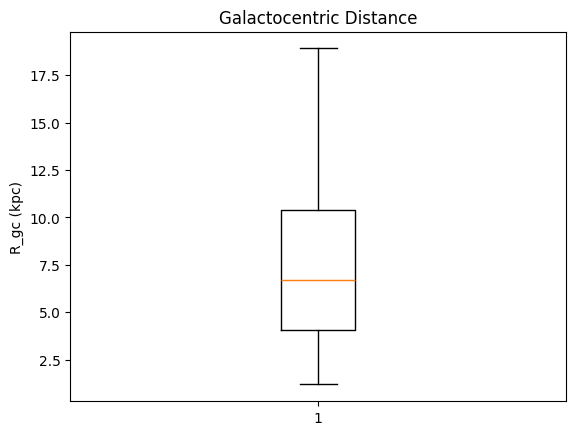

Mean R_gc = 7.723529411764705
Q1= [4.05]
Q3= [10.4]
IQR = 6.3500000000000005
outlier cutoff = [-5.475] [19.925]
max= R_gc    18.9
dtype: float64
min= R_gc    1.2
dtype: float64


In [ ]:
# Galactocentric Distance Data Analysis

R_gc = pd.DataFrame(R_gc)   # This makes the column of R_gc easier to put into a box plot 
plt.boxplot(R_gc)           # also this tiny section of code is stolen from matildas section tysm <3
plt.title('Galactocentric Distance')
plt.ylabel('R_gc (kpc)')
plt.show()

print('Mean R_gc =', np.mean(R_gc))
Q1_R_gc = quantile(R_gc, [0.25]) # define 1st quartile of metallicity
Q3_R_gc = quantile(R_gc,[0.75])  # define 3rd quartile of metallicity
iqr_R_gc = stats.iqr(R_gc)       # finds IQR (could also be done by Q3-Q1)
print('Q1=',Q1_R_gc)
print('Q3=',Q3_R_gc)
print('IQR =', iqr_R_gc)
print('outlier cutoff =', Q1_R_gc-1.5*iqr_R_gc, Q3_R_gc+1.5*iqr_R_gc) # Finds the cutoff below and above which values are considered outliers
print('max=', R_gc.max())        # Finds maximum value in the metallicity column
print('min=', R_gc.min())        # Finds the minimum value in the metallicity column

# No outliers Found


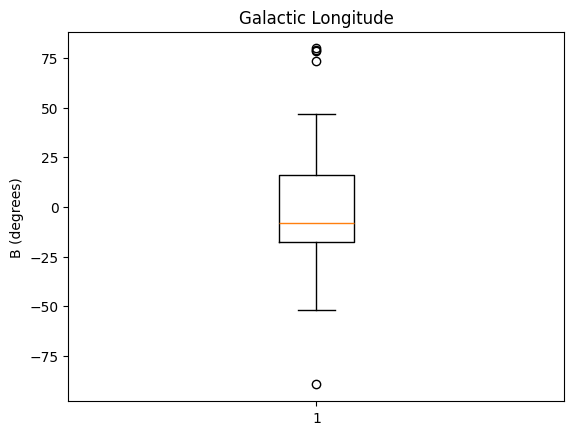

Mean G_longitude = -0.6409803921568631
Q1= [-17.435]
Q3= [15.835]
IQR = 33.27
outlier cutoff = [-67.34] [65.74]
max= B    79.76
dtype: float64
min= B   -89.38
dtype: float64


In [ ]:
# Galactic Longitude Analysis

G_Longitude = pd.DataFrame(G_Longitude)   # This makes the column of R_gc easier to put into a box plot 
plt.boxplot(G_Longitude)           # also this tiny section of code is stolen from matildas section tysm <3
plt.title('Galactic Longitude')
plt.ylabel('B (degrees)')
plt.show()

print('Mean G_longitude =', np.mean(G_Longitude))
Q1_G_longitude = quantile(G_Longitude, [0.25]) # define 1st quartile of metallicity
Q3_G_longitude = quantile(G_Longitude,[0.75])  # define 3rd quartile of metallicity
iqr_G_longitude = stats.iqr(G_Longitude)       # finds IQR (could also be done by Q3-Q1)
print('Q1=',Q1_G_longitude)
print('Q3=',Q3_G_longitude)
print('IQR =', iqr_G_longitude)
print('outlier cutoff =', Q1_G_longitude-1.5*iqr_G_longitude, Q3_G_longitude+1.5*iqr_G_longitude) # Finds the cutoff below and above which values are considered outliers
print('max=', G_Longitude.max())        # Finds maximum value in the metallicity column
print('min=', G_Longitude.min())        # Finds the minimum value in the metallicity column

# No outliers Found
